In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Wisconsin Breast Cancer dataset
df = pd.read_csv("wdbc.data", header=None)

# Check the size of the dataset
print("Dataset shape:", df.shape)

# Display the first five records
df.head()


Dataset shape: (569, 32)


,0,1,2,3,4,5,6,7,8,9,...,22,23,24,25,26,27,28,29,30,31
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [2]:

# Check for missing values in each column
print(df.isnull().sum())

# Calculate the total number of missing values
print("Total missing values:", df.isnull().sum().sum())


0     0
1     0
2     0
3     0
4     0
5     0
6     0
7     0
8     0
9     0
10    0
11    0
12    0
13    0
14    0
15    0
16    0
17    0
18    0
19    0
20    0
21    0
22    0
23    0
24    0
25    0
26    0
27    0
28    0
29    0
30    0
31    0
dtype: int64
Total missing values: 0


In [3]:

# Check for duplicate rows
print("Duplicate rows:", df.duplicated().sum())


Duplicate rows: 0


In [6]:

# Define the names of the 10 cell characteristics
features = [
    'radius', 'texture', 'perimeter', 'area',
    'smoothness', 'compactness', 'concavity',
    'concave_points', 'symmetry', 'fractal_dimension'
]

# Create names for all 30 measurements
columns = ['id', 'diagnosis']

for measurement in ['mean', 'se', 'worst']:
    for feature in features:
        columns.append(f'{feature}_{measurement}')

# Assign column names to the dataset
df.columns = columns

# Display the first five rows
df.head()


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


### Assigning column names 
The dataset was loaded without column headings. Descriptive names were assigned to all 32 columns so that it is easy to identify and interpret the variablkes when conducting analysis. 

### 1. DATA SELECTION JUSTIFICATION

The Wisconsin Diagnostic Breast Cancer dataset was sourced from UCI Machine Learning Repository. It was selected because it has information that could be used to classify tumours as either benign or malignant. This makes it suitable because the medical aid scheme requested for a classification task. The datset has 569 observations and 32 columns, 30 of these colums are numerical features. The numerical features describe characteristics of cell nuclei, including radius, texture, perimeter, area and smoothness.

The target variable is the diagnosis which has two categories; benign (B) and malignant (M). This makes the dataset suitable for binary classification algorithms like Random Forest and Logistic Regression.

The quality of the dataset was assessed and the results show that there are no missing values and duplicates. The dataset has a moderate class imbalance with 357 benign cases (62.7%) and 121 malignant cases (37.3%). This will be taken into account during model training and evaluation to avoid incorrect classifiction. 

The limitation is that the dataset has historical diagnostic measurements rather than South African medical aid records. Also, there is no in fromation about medical aid membership or benefits. So even though this data is suitable for this task, it still requires further validation using South African data before it can be applied in real world scenarios.



### 2. ALGORITHM SELECTION JUSTIFICATION

Logistic Regression is selected as the classification algorithm becuase the datset has a binary target variable where tumours are classified as either benign or malignant. The algorithm uses the numerical features of the datset to estimate the probability that a tumour belongs to a particular category. The results of Logistic Regression are easy to interpret which is important in the healthcare sector because understanding the factors influencing predictions is valuable here. It is also suitable for a dtaset of 659 observations and can provide a useful starting point for evaluating classification performance. 

Randoem Forest and Decision Tree were also considered. Random Forest can captuore complex relationships but it is not as straightforward to interpret as Logistic Regression. On the other hand. Decision Trees are easy to understand but can overfit training data. Random Forest will be used as a comparison model to determine whether a more complex  algorithm improves classfication performance. This will help in determining if Logistic Regression offers suitable balnce between predictive performance and interpretability.

### 4.1 EXPLORATORY DATA ANALYSIS
This section is for understanding the data struture, identifying pattersns and to examine characteristic that may help differentiate between benign and malignant tumours. This analysis will include descriptivr statistics, class distribution, relationships  between varaibles and potential outliers

In [7]:

# Display information about the dataset
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave_points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

In [8]:

# descriptive statistics
descriptive_stats = df.drop(columns=['id', 'diagnosis']).describe().T

descriptive_stats


,count,mean,std,min,25%,50%,75%,max
radius_mean,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
texture_mean,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
perimeter_mean,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
area_mean,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
smoothness_mean,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
compactness_mean,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
concavity_mean,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
concave_points_mean,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
symmetry_mean,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
fractal_dimension_mean,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


### DESCRIPTIVE STATS INTERPRETATION
The descriptive statistics show that the numerical feautures have different measurement scales. For instance, the mean area is 654.89 while the mean smoothness is 0.0964. This means that when training Logistic Regression, feauture scaling will be needed.
Some of the features are also showing some variance. The standard deviation of the eorst area measurement is 569.36. Which shows that the value differ accross observations. Also, the maximum values of certain features are much higher than their medians. This suggests possible outliers and right skewed distributions whivh will be investigated further during the EDA.

### CLASS DISTRIBUTION

In [9]:

# Count benign and malignant cases
class_counts = df['diagnosis'].value_counts()

# Calculate percentages
class_percentages = df['diagnosis'].value_counts(normalize=True) * 100

print("Class Distribution:")
print(class_counts)

print("\nClass Percentages:")
print(class_percentages.round(2))


Class Distribution:
diagnosis
B    357
M    212
Name: count, dtype: int64

Class Percentages:
diagnosis
B    62.74
M    37.26
Name: proportion, dtype: float64


The dataset has 357 benign cases (62.74%) and 212 malignant cases (37.26%). This indicates a moderate class imbalance as benign cases make up a larger proportion of the dataset. This imbalance will be taken into account suirng model training and evaluation. There will be more focus on recall for malignant cases because incorrectly classifying a malignant tumour as benign could have serious consequences.

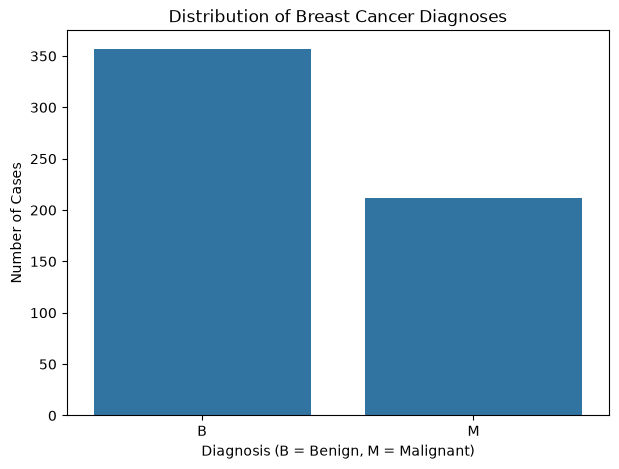

In [10]:

# Visualise the distribution of benign and malignant cases
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='diagnosis',
    order=['B', 'M']
)

plt.title('Distribution of Breast Cancer Diagnoses')
plt.xlabel('Diagnosis (B = Benign, M = Malignant)')
plt.ylabel('Number of Cases')

plt.show()


### INTERPRETATION OF CLASS DISTRIBUTION
The bar chat shows that benign tumours make up 62.74% of the observations compared to 37.26% for malignant tumours. This is a confirmation of the moderate class imbalance. Since malignant cases are not as common, accuracy alone may not provide a full picture of model performance. As a result, recall for malignant cases will be an important evaluation measure to reduce the risk of failing to identify tumours.

### FEATURE DISTRIBUTION

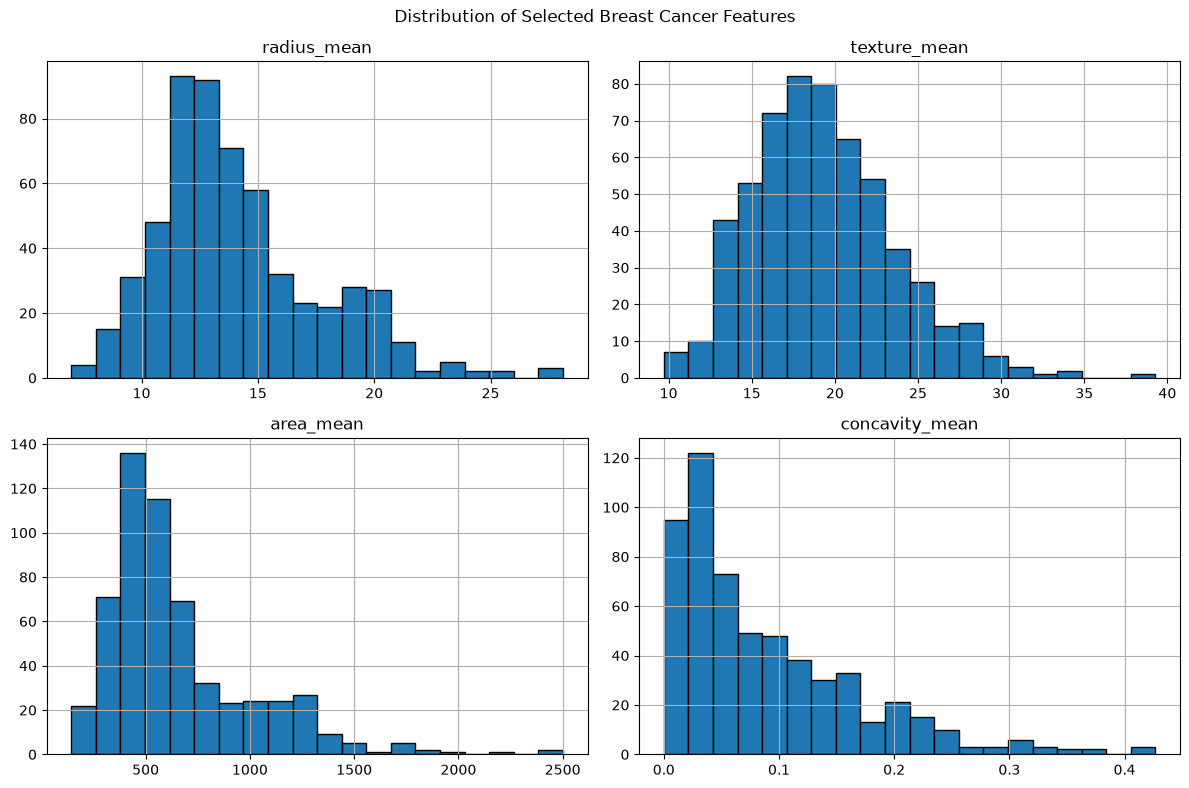

In [11]:

# Plot histograms for selected numerical features
selected_features = [
    'radius_mean',
    'texture_mean',
    'area_mean',
    'concavity_mean'
]

df[selected_features].hist(
    figsize=(12, 8),
    bins=20,
    edgecolor='black'
)

plt.suptitle('Distribution of Selected Breast Cancer Features')
plt.tight_layout()
plt.show()


### INTERPRETATION
The histograms show that the selected numerical features have different distributions. Mean radius and mean texture are concentrated around their cental values evenm though they both have some higher observations. Mean area and mean concavity are more right skewed with most values concentrated at the lower end and few unusually higher measurements. These findings tell us that some features may have outliers. This will be investigated further using boxplots and also help determine if they should be kept during model development.

### BOX PLOT TO IDENTIFY OUTLIERS


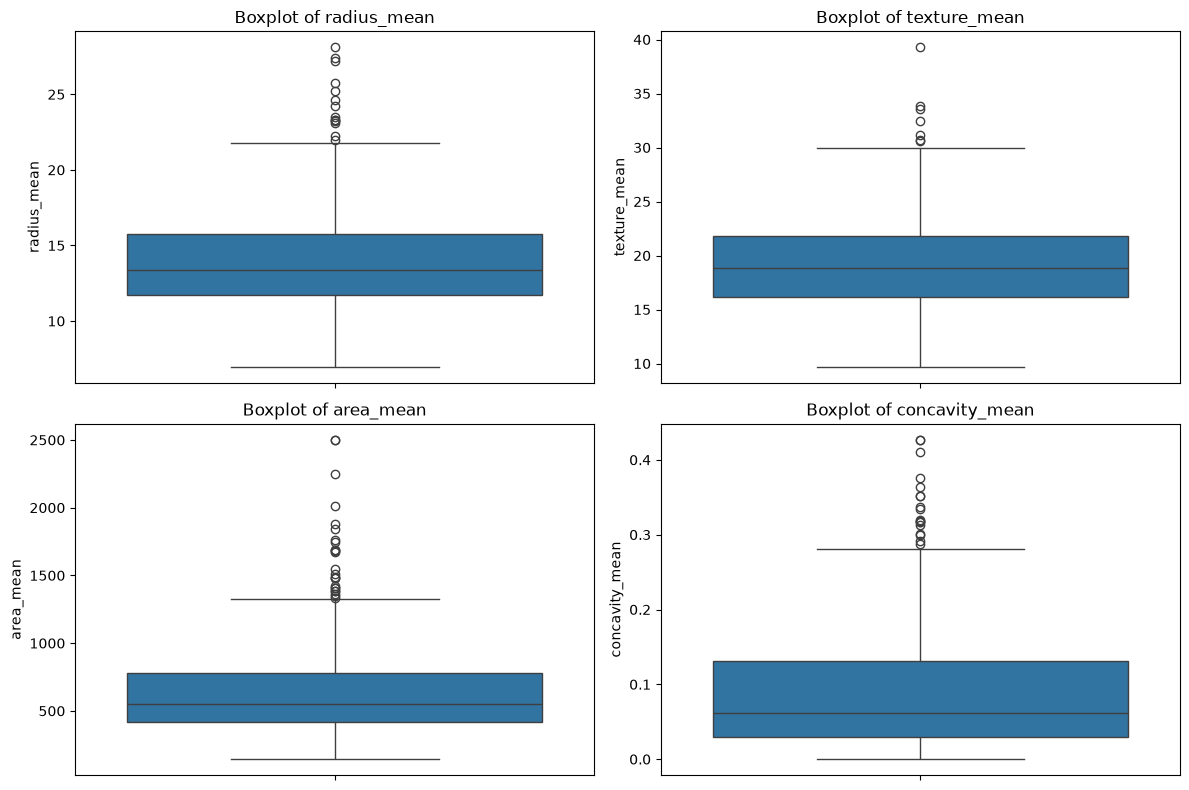

In [12]:

# Create boxplots to identify potential outliers
selected_features = [
    'radius_mean',
    'texture_mean',
    'area_mean',
    'concavity_mean'
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, feature in zip(axes.flatten(), selected_features):
    sns.boxplot(y=df[feature], ax=ax)
    ax.set_title(f'Boxplot of {feature}')
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()


### OUTLIER ANALYSIS
The boxplots show potential outliers in all four selected features,especially mean radius, mean area and mean concavity. Mean area has a few unusually high values with the maximum reaching 2501. These results support the right skewed distributions observed in the histograms. These pontential outliers will be kept at these stage because they might represent real tumour characteristics rather than data errors. Keeping them until further investigation will prevent losing useful information for identifying malignant tumours.

### FEATURE COMPARISON BT DIAGNOSIS



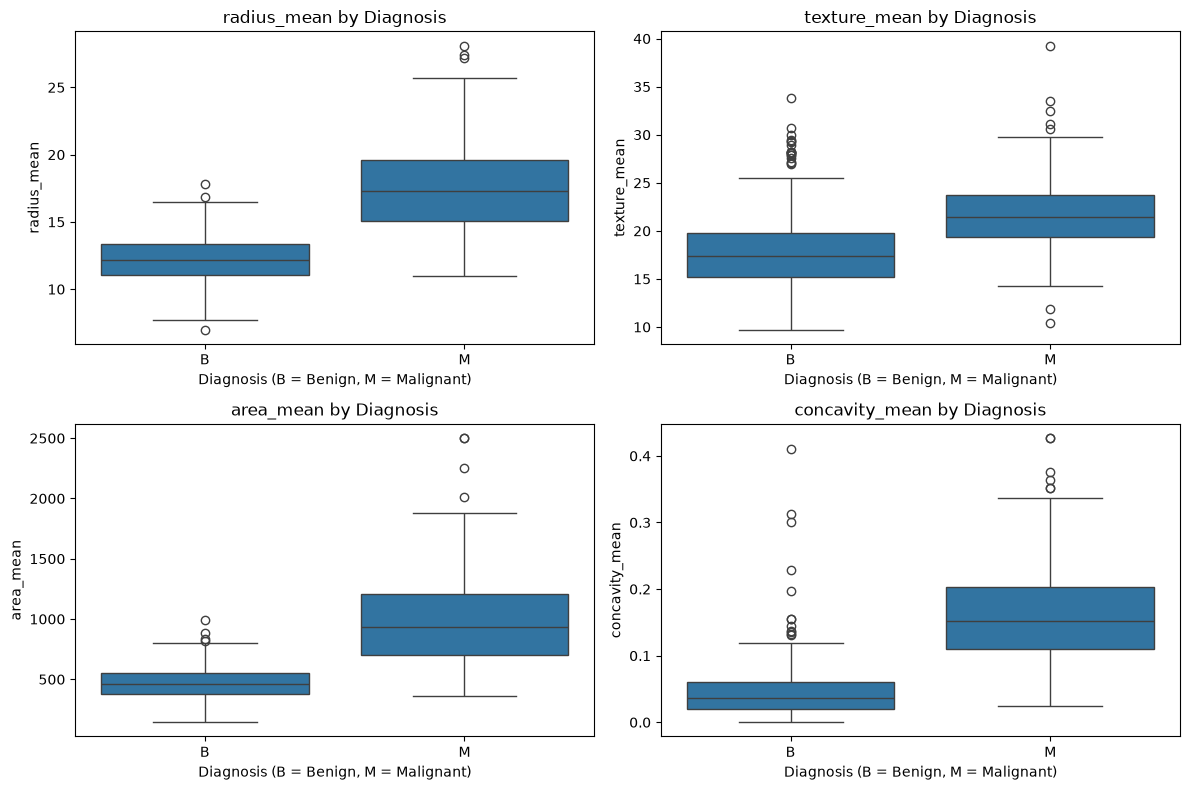

In [13]:

# Compare selected features between benign and malignant cases
selected_features = [
    'radius_mean',
    'texture_mean',
    'area_mean',
    'concavity_mean'
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, feature in zip(axes.flatten(), selected_features):
    sns.boxplot(
        data=df,
        x='diagnosis',
        y=feature,
        order=['B', 'M'],
        ax=ax
    )
    ax.set_title(f'{feature} by Diagnosis')
    ax.set_xlabel('Diagnosis (B = Benign, M = Malignant)')
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()


### INTERPRETATION
The boxplots show that malignant tumours have higher mean radius, arae, texture and concavity measurements than benign tumours. These differences are more visible for radius, area and conacavity which suggests that these features may be useful for predicting tumour diagnosis. There is however some overlap between the two groups which means that individual measurements may not be enough for accurate classification. These finfings support using a classification model that considers several features together.

### CORRELATION AANALYSIS

In [15]:

# Calculate correlations between numerical features
correlation_matrix = df.drop(
    columns=['id', 'diagnosis']
).corr()

# Find highly correlated feature pairs
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

high_correlations = (
    upper_triangle.stack()
    .reset_index()
)

high_correlations.columns = [
    'Feature 1',
    'Feature 2',
    'Correlation'
]

# Display feature pairs with strong correlations
high_correlations = high_correlations[
    high_correlations['Correlation'].abs() >= 0.85
].sort_values('Correlation', ascending=False)

high_correlations


,Feature 1,Feature 2,Correlation
2,radius_mean,perimeter_mean,0.997855
622,radius_worst,perimeter_worst,0.993708
3,radius_mean,area_mean,0.987357
63,perimeter_mean,area_mean,0.986507
623,radius_worst,area_worst,0.984015
683,perimeter_worst,area_worst,0.977578
312,radius_se,perimeter_se,0.972794
82,perimeter_mean,perimeter_worst,0.970387
20,radius_mean,radius_worst,0.969539
80,perimeter_mean,radius_worst,0.969476


### INTERPRETATION
The correlation analysis identified several strongly related numerical features. Mean radius and mean perimeter had the strongest coreelation (r=0.9979), followed by worst radius and worst perimeter (r = 0.9937). Mean radius and mean area were also highly correlated (r=0.9874). These results show that some features have similar infromation, which may lead to multicollinearity when training Logistic Regression. This could make the coffiecients of the model more difficult to interpret. These findings will be taken into account during feature selection where highly correlated predictors will be looked into to see if they are all neccessary.

### CORRRELATION HEATMAP

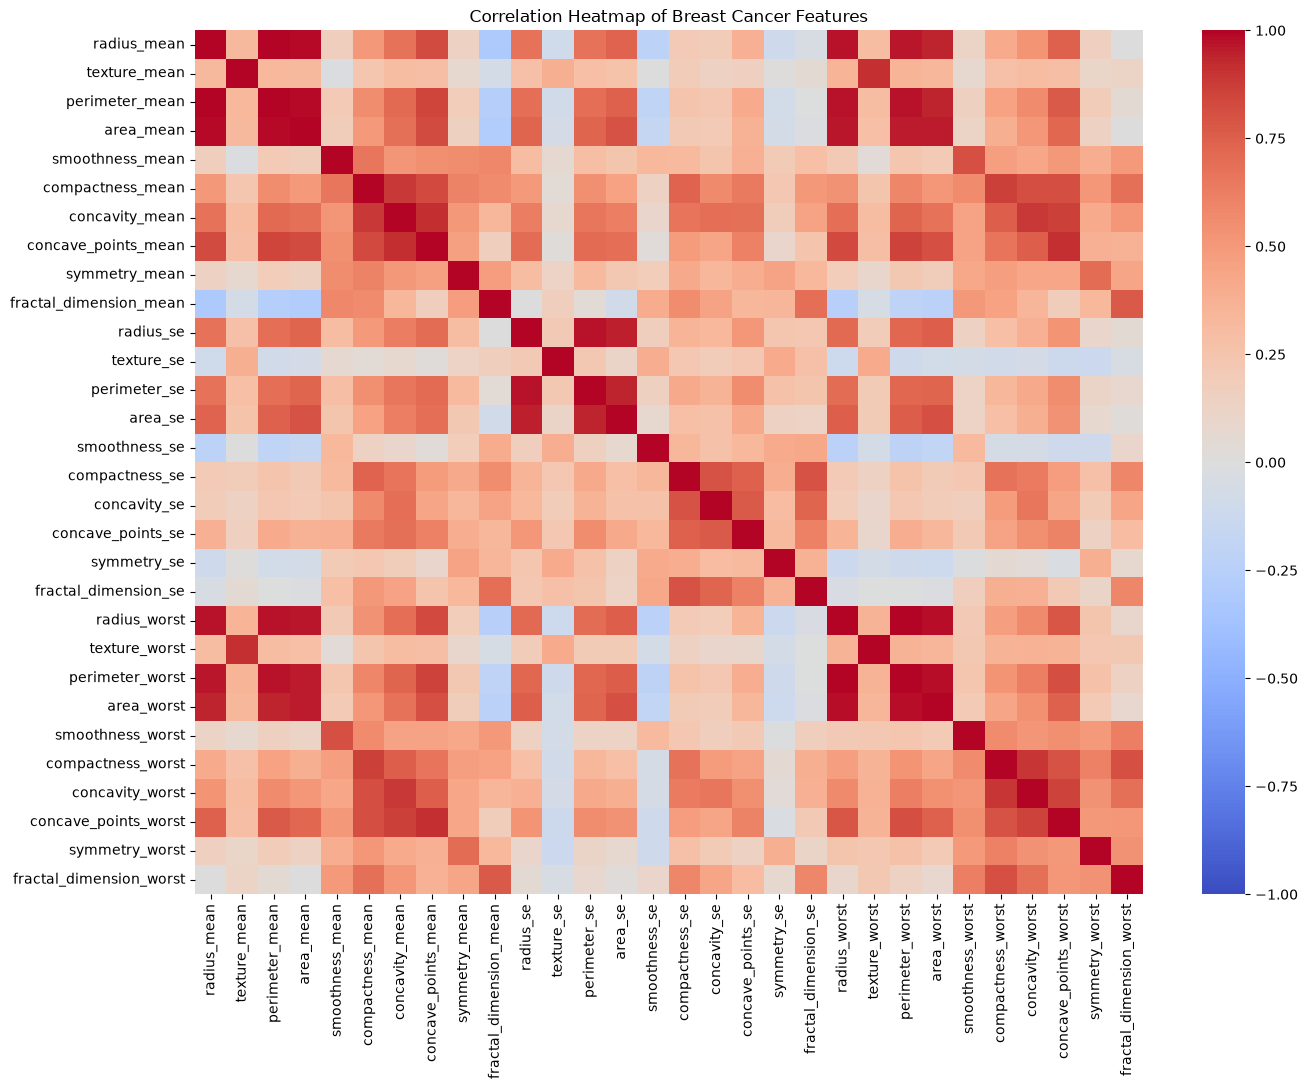

In [16]:

# Create a correlation heatmap for numerical features
plt.figure(figsize=(14, 11))

sns.heatmap(
    correlation_matrix,
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1
)

plt.title('Correlation Heatmap of Breast Cancer Features')
plt.tight_layout()
plt.show()


### INTERPRETAION
The heatmap shows strong positive correlations between several numerical features; radius, perimetwe and area measurements. Similar relationships are also seen with mean and worst measurements. This susggests that some features have overlapping information. Other features such as fractal dimension show weaker correlations with certain measurements. The strong correlations indicate possible multicollinearity which will be considered duirng feature selection to improve the interpretability of the Logistic Regression model.

### CORRELATIONS WITH DIAGNOSIS

In [18]:

# Encode diagnosis for correlation analysis
df['diagnosis_encoded'] = df['diagnosis'].map({'B': 0, 'M': 1})

# Calculate correlations with diagnosis
diagnosis_correlations = (
    df.drop(columns=['id', 'diagnosis'])
    .corr()['diagnosis_encoded']
    .drop('diagnosis_encoded')
    .sort_values(ascending=False)
)

# Display the correlations
diagnosis_correlations


concave_points_worst       0.793566
perimeter_worst            0.782914
concave_points_mean        0.776614
radius_worst               0.776454
perimeter_mean             0.742636
area_worst                 0.733825
radius_mean                0.730029
area_mean                  0.708984
concavity_mean             0.696360
concavity_worst            0.659610
compactness_mean           0.596534
compactness_worst          0.590998
radius_se                  0.567134
perimeter_se               0.556141
area_se                    0.548236
texture_worst              0.456903
smoothness_worst           0.421465
symmetry_worst             0.416294
texture_mean               0.415185
concave_points_se          0.408042
smoothness_mean            0.358560
symmetry_mean              0.330499
fractal_dimension_worst    0.323872
compactness_se             0.292999
concavity_se               0.253730
fractal_dimension_se       0.077972
symmetry_se               -0.006522
texture_se                -0

### INTERPRETATION
The correlation analysis shows that several features are strongly associated with tumour diagnosis. The strongest relationship was seen for worst concave points (r = 0.7936), followed by worst perimeter (r = 0.7829), mean concave points (r = 0.7766) and worst radius (r = 0.7765).These positive correlations suggest that higher measurements are generally associated with malignant tumours. Some features, including mean fractal dimension and symmetry standard error, showed very weak correlations with diagnosis.

The findings suggest that concave points, perimeter, radius and area measurements may be useful predictors. However, some of these features are also highly correlated with one another. This will be considered during feature selection to avoid unnecessary duplication of information.

### BARCHART FOR STRONGEST CORRELATIONS WITH DIAGNOSIS

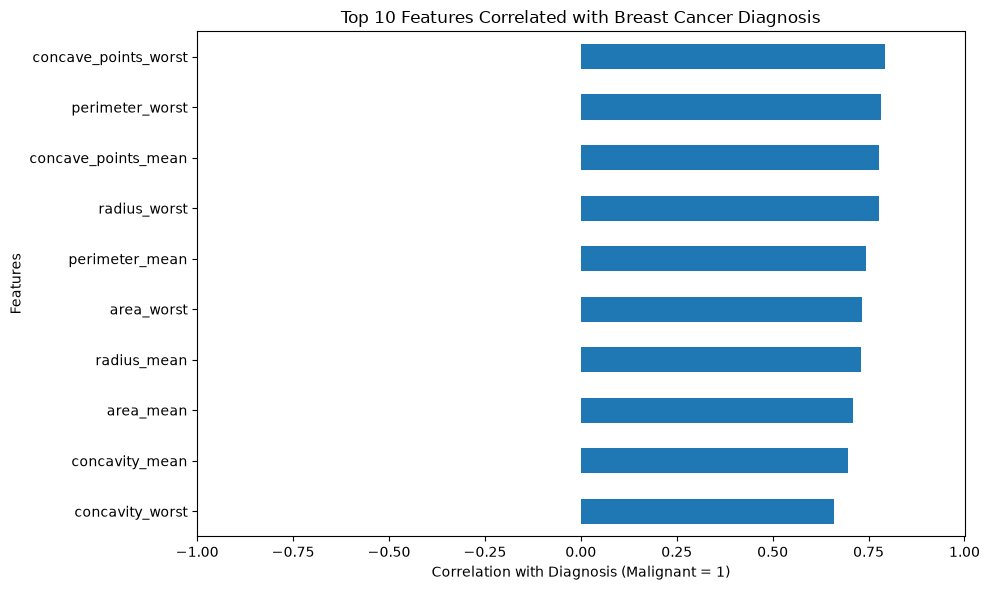

In [19]:

# Select the 10 features with the strongest absolute correlations
top_features = diagnosis_correlations.abs().nlargest(10).index

top_correlations = diagnosis_correlations.loc[top_features].sort_values()

# Create a horizontal bar chart
plt.figure(figsize=(10, 6))

top_correlations.plot(kind='barh')

plt.title('Top 10 Features Correlated with Breast Cancer Diagnosis')
plt.xlabel('Correlation with Diagnosis (Malignant = 1)')
plt.ylabel('Features')
plt.xlim(-1, 1)
plt.tight_layout()
plt.show()


### INTERPRETATION
The bar chart shows that worst concave points, worst perimeter and mean concave points have the strongest positive relationships with tumour diagnosis. This suggests that these measurements may be useful for differentiating between benign and malignant tumours. However, several of the highly ranked features are also strongly correlated with one another. Therefore, their individual relationships with diagnosis will be considered alongside multicollinearity and model performance when selecting predictors.

### 4.2 FEATURE SELECTION
Feature selection will be used to identify predictors that are useful for classiffying tumours while reducing unnecessary overlap between variables. The datset will first be divided into training and testing sets to make sure feature selcetion is performed without using information from test data


In [21]:

from sklearn.model_selection import train_test_split

# Define predictor variables and target
X = df.drop(columns=['id', 'diagnosis', 'diagnosis_encoded'])
y = df['diagnosis_encoded']

# Split data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)


Training features: (455, 30)
Testing features: (114, 30)
Training labels: (455,)
Testing labels: (114,)


The dataset was divided into 80% training data (455 observations) and 20% testing data (114 observations). Stratified sampling was used to maintain approximately the same proportion of benign and malignant cases in both sets. The training data will be used for feature selection and model development, while the testing data will be reserved for evaluating model performance on unseen observations.

### IDENTIFY IMPORTANT FEATURES

In [23]:

# Calculate correlations with diagnosis using training data only
train_correlations = X_train.corrwith(y_train)

# Rank features by absolute correlation
feature_ranking = (
    train_correlations.abs()
    .sort_values(ascending=False)
    .to_frame(name='Absolute Correlation')
)

# Display the 15 highest-ranked features
feature_ranking.head(15)


,Absolute Correlation
concave_points_worst,0.786306
perimeter_worst,0.782881
radius_worst,0.777602
concave_points_mean,0.775737
perimeter_mean,0.740027
area_worst,0.731761
radius_mean,0.728160
area_mean,0.703893
concavity_mean,0.683688
concavity_worst,0.643116


### FEATURE RANKING

The training data was used to identify features with the strongest relationships with tumour diagnosis. Worst concave points had the highest absolute correlation (0.7863), followed by worst perimeter (0.7829), worst radius (0.7776) and mean concave points (0.7757). Although these features show strong relationships with diagnosis, some are also highly correlated with one another. Therefore, multicollinearity will be considered before selecting the final predictors for Logistic Regression.

### MULTICOLLINEARITY

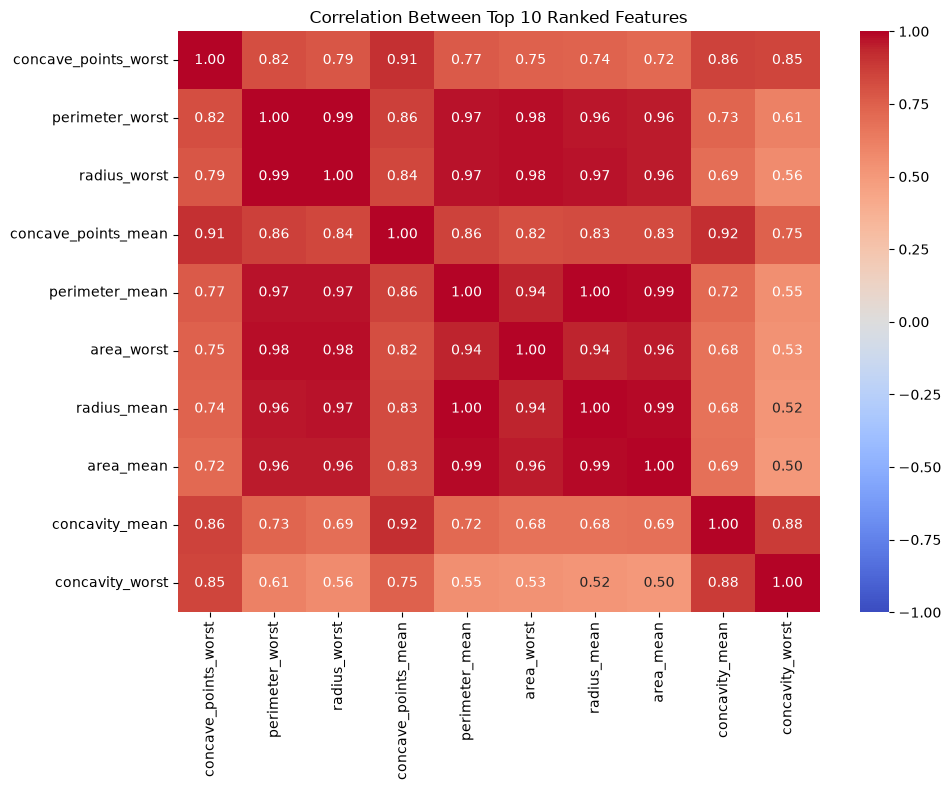

In [24]:

# Select the 10 highest-ranked features
top_10_features = feature_ranking.head(10).index.tolist()

# Calculate correlations using training data only
top_10_corr = X_train[top_10_features].corr()

# Display correlation heatmap
plt.figure(figsize=(10, 8))

sns.heatmap(
    top_10_corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Between Top 10 Ranked Features')
plt.tight_layout()
plt.show()


### Multicollinearity Analysis

The heatmap shows strong positive correlations between several of the highest-ranked features. Worst perimeter and worst radius have a correlation of approximately 0.99, while mean perimeter and mean radius are almost perfectly correlated. Mean concave points and mean concavity are also strongly related (r = 0.92). These findings suggest that some predictors contain overlapping information. Including all of them may make Logistic Regression coefficients more difficult to interpret. Therefore, a smaller feature set will be investigated and compared with the full model to determine whether reducing the number of predictors affects classification performance.

In [25]:

# Define a smaller candidate feature set
selected_features = [
    'concave_points_worst',
    'perimeter_worst',
    'concavity_worst',
    'texture_worst'
]

# Examine correlations among the selected features
selected_corr = X_train[selected_features].corr()

print("Selected candidate features:")
print(selected_features)

print("\nCorrelation matrix:")
print(selected_corr.round(3))


Selected candidate features:
['concave_points_worst', 'perimeter_worst', 'concavity_worst', 'texture_worst']

Correlation matrix:
                      concave_points_worst  perimeter_worst  concavity_worst  \
concave_points_worst                 1.000            0.816            0.849   
perimeter_worst                      0.816            1.000            0.611   
concavity_worst                      0.849            0.611            1.000   
texture_worst                        0.360            0.371            0.360   

                      texture_worst  
concave_points_worst          0.360  
perimeter_worst               0.371  
concavity_worst               0.360  
texture_worst                 1.000  


#### Evaluation of Selected Features

Four candidate features were examined: worst concave points, worst perimeter, worst concavity and worst texture. These features were considered because they represent different tumour characteristics and showed potentially useful relationships with diagnosis.The strongest correlation among the selected features was between worst concave points and worst concavity (r = 0.849). Worst texture had weaker correlations with the other three features, ranging from 0.360 to 0.371.

These results suggest that the reduced feature set contains less overlapping information than some of the original predictors. However, the selected features will still need to be evaluated through model training to determine whether they provide sufficient predictive performance.

In [26]:

# Full feature set (30 predictors)
X_train_full = X_train.copy()
X_test_full = X_test.copy()

# Reduced feature set (4 predictors)
X_train_reduced = X_train[selected_features].copy()
X_test_reduced = X_test[selected_features].copy()

# Confirm the dimensions
print("Full training set:", X_train_full.shape)
print("Reduced training set:", X_train_reduced.shape)

print("Full testing set:", X_test_full.shape)
print("Reduced testing set:", X_test_reduced.shape)


Full training set: (455, 30)
Reduced training set: (455, 4)
Full testing set: (114, 30)
Reduced testing set: (114, 4)


#### PREP FOR FEATURE SETS

Two feature sets were prepared for model training. The full dataset contains 30 numerical predictors, while the reduced dataset contains four selected features: worst concave points, worst perimeter, worst concavity and worst texture. Both feature sets use the same 455 training observations and 114 testing observations. Comparing the models will help determine whether reducing the number of predictors affects classification performance.

### 4.3 MODEL TRAINING
Logistic Regression was selected as the main classification algorithm because the target variable has two categories: benign and malignant. The model will be trained using both the full and reduced feature sets.

StandardScaler will be included in the training pipeline to standardise the numerical features. Five-fold stratified cross-validation will be used to compare model performance while maintaining the class distribution across the folds. Recall for malignant cases will be prioritised because failing to identify a malignant tumour is a particularly important classification error.

In [27]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Create Logistic Regression pipeline
lr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Set up 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate the full feature set
full_recall = cross_val_score(
    lr_pipeline,
    X_train_full,
    y_train,
    cv=cv,
    scoring='recall'
)

# Evaluate the reduced feature set
reduced_recall = cross_val_score(
    lr_pipeline,
    X_train_reduced,
    y_train,
    cv=cv,
    scoring='recall'
)

print("Full Model Recall Scores:", full_recall.round(4))
print("Full Model Mean Recall:", round(full_recall.mean(), 4))

print("\nReduced Model Recall Scores:", reduced_recall.round(4))
print("Reduced Model Mean Recall:", round(reduced_recall.mean(), 4))


Full Model Recall Scores: [0.8824 0.9706 1.     0.9412 0.9706]
Full Model Mean Recall: 0.9529

Reduced Model Recall Scores: [0.9118 0.9706 0.9118 0.8824 0.9706]
Reduced Model Mean Recall: 0.9294


#### CROSS VALIDATION RESULTS

Five-fold stratified cross-validation was used to compare Logistic Regression models trained on the full and reduced feature sets. The full model achieved a mean recall of 95.29%, compared with 92.94% for the reduced model.

The full model performed slightly better at identifying malignant tumours, suggesting that the additional predictors may provide useful information. However, the reduced model also achieved relatively high recall while using fewer features. Further evaluation using precision, F1-score and ROC-AUC is needed before selecting the preferred model.

### COMPARE OTHER PERFORMANCE METRICS

In [28]:

from sklearn.model_selection import cross_validate

# Define evaluation metrics
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

# Evaluate full model
full_results = cross_validate(
    lr_pipeline,
    X_train_full,
    y_train,
    cv=cv,
    scoring=scoring
)

# Evaluate reduced model
reduced_results = cross_validate(
    lr_pipeline,
    X_train_reduced,
    y_train,
    cv=cv,
    scoring=scoring
)

# Create comparison table
comparison = pd.DataFrame({
    'Metric': scoring,
    'Full Model': [
        full_results[f'test_{metric}'].mean()
        for metric in scoring
    ],
    'Reduced Model': [
        reduced_results[f'test_{metric}'].mean()
        for metric in scoring
    ]
})

comparison.round(4)


,Metric,Full Model,Reduced Model
0,accuracy,0.9736,0.9560
1,precision,0.9771,0.9523
2,recall,0.9529,0.9294
3,f1,0.9640,0.9402
4,roc_auc,0.9958,0.9899


#### LOGISTICT REGRESSION MODEL COMPARISON

The cross-validation results show that the full Logistic Regression model performed better than the reduced model across all five evaluation metrics. The full model achieved an accuracy of 97.36%, precision of 97.71%, recall of 95.29%, F1-score of 96.40% and ROC-AUC of 0.9958.

The reduced model also performed well but achieved lower scores across all metrics. In particular, its recall was 92.94%, compared with 95.29% for the full model. This suggests that some of the additional features contribute useful information for identifying malignant tumours.

Based on these results, the full model will be retained as the preferred Logistic Regression candidate. However, its performance will still be compared with Random Forest before the final model is selected.

### TRAIN AND EVALUATE RANDOM FOREST

In [31]:

from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Evaluate Random Forest using 5-fold cross-validation
rf_results = cross_validate(
    rf_model,
    X_train_full,
    y_train,
    cv=cv,
    scoring=scoring
)

# Display performance results
rf_comparison = pd.DataFrame({
    'Metric': scoring,
    'Random Forest': [
        rf_results[f'test_{metric}'].mean()
        for metric in scoring
    ]
})

rf_comparison.round(4)


,Metric,Random Forest
0,accuracy,0.9648
1,precision,0.9641
2,recall,0.9412
3,f1,0.9519
4,roc_auc,0.9889


#### LOGISTIC VS RANDOM FOREST

The cross-validation results show that Logistic Regression performed slightly better than Random Forest across all evaluation metrics. Logistic Regression achieved an accuracy of 97.36%, recall of 95.29%, F1-score of 96.40% and ROC-AUC of 0.9958. In comparison, Random Forest achieved an accuracy of 96.48%, recall of 94.12%, F1-score of 95.19% and ROC-AUC of 0.9889.

Both models performed well, but Logistic Regression achieved higher recall, which is particularly important for identifying malignant tumours. Based on these results, Logistic Regression was selected as the preferred model for final testing.

### 5. MODEL EVALUATION AND INTERPRETATION

### TRAIN FINAL LOGISTIC REGRESSION MODEL

In [32]:

# Train the selected Logistic Regression model
final_lr_model = lr_pipeline.fit(
    X_train_full,
    y_train
)

# Make predictions on the test set
y_pred = final_lr_model.predict(X_test_full)

# Predict probabilities for malignant cases
y_prob = final_lr_model.predict_proba(X_test_full)[:, 1]

print("Model training completed.")
print("Number of test predictions:", len(y_pred))


Model training completed.
Number of test predictions: 114


In [33]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Calculate test performance metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

# Display results
print("Final Logistic Regression Test Results")
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))
print("ROC-AUC:", round(roc_auc, 4))

# Display confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Final Logistic Regression Test Results
Accuracy: 0.9649
Precision: 0.975
Recall: 0.9286
F1-score: 0.9512
ROC-AUC: 0.996

Confusion Matrix:
[[71  1]
 [ 3 39]]


#### Final Logistic Regression Model Evaluation

The final Logistic Regression model achieved an accuracy of 96.49%, precision of 97.50%, recall of 92.86%, F1-score of 95.12% and ROC-AUC of 0.9960 on the test dataset.The confusion matrix shows that the model correctly classified 71 benign and 39 malignant tumours. However, one benign tumour was incorrectly classified as malignant, while three malignant tumours were incorrectly classified as benign.

Although the model demonstrated strong overall performance, the three false negatives remain a concern because they represent malignant cases that were missed. This highlights the importance of prioritising recall when developing a breast cancer classification model. The model may be useful for supporting diagnostic decisions, but it should not replace clinical assessment.

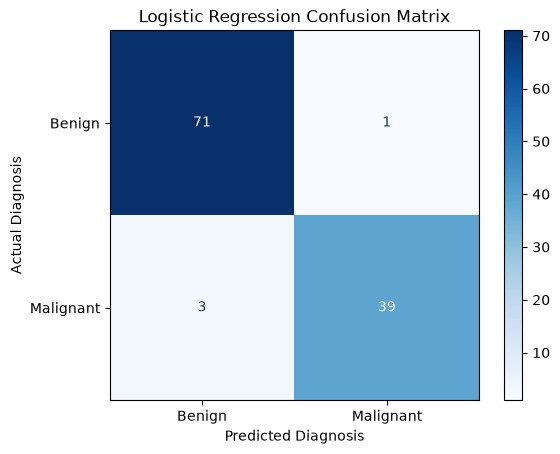

In [34]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Create confusion matrix visualisation
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=['Benign', 'Malignant'],
    cmap='Blues',
    values_format='d'
)

plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted Diagnosis')
plt.ylabel('Actual Diagnosis')
plt.show()


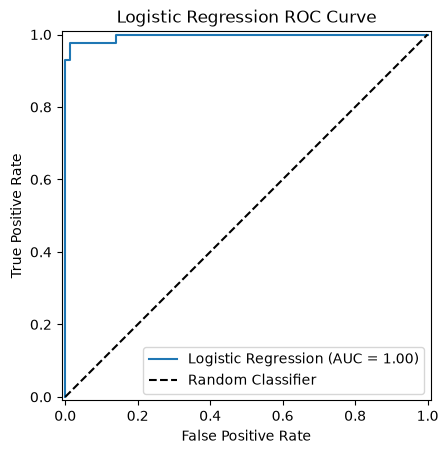

In [35]:

from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

# Plot ROC curve for the final Logistic Regression model
RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    name='Logistic Regression'
)

# Add reference line
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')

plt.title('Logistic Regression ROC Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()


#### ROC Curve Interpretation

The ROC curve shows that the Logistic Regression model performs well in distinguishing between benign and malignant tumours. The curve is positioned close to the top-left corner and remains above the diagonal reference line, indicating strong classification performance.

The model achieved a ROC-AUC of 0.9960, suggesting excellent discrimination between the two classes. However, the confusion matrix showed that three malignant cases were incorrectly classified as benign at the default classification threshold. Therefore, despite the high ROC-AUC, reducing false negatives remains an important consideration.

In [36]:

# Extract coefficients from the trained model
coefficients = final_lr_model.named_steps['model'].coef_[0]

# Create coefficient table
coefficient_df = pd.DataFrame({
    'Feature': X_train_full.columns,
    'Coefficient': coefficients
})

# Sort coefficients from highest to lowest
coefficient_df = coefficient_df.sort_values(
    by='Coefficient',
    ascending=False
)

print("Top 10 Positive Coefficients:")
display(coefficient_df.head(10))

print("\nTop 10 Negative Coefficients:")
display(coefficient_df.tail(10).sort_values('Coefficient'))


Top 10 Positive Coefficients:


,Feature,Coefficient
21,texture_worst,1.434093
10,radius_se,1.233325
28,symmetry_worst,1.061264
7,concave_points_mean,0.952813
26,concavity_worst,0.911406
13,area_se,0.909029
23,area_worst,0.900477
20,radius_worst,0.896968
6,concavity_mean,0.782298
12,perimeter_se,0.748295



Top 10 Negative Coefficients:


,Feature,Coefficient
15,compactness_se,-0.906925
19,fractal_dimension_se,-0.593876
5,compactness_mean,-0.439546
11,texture_se,-0.407611
18,symmetry_se,-0.330658
25,compactness_worst,-0.173488
8,symmetry_mean,-0.163991
16,concavity_se,-0.092341
9,fractal_dimension_mean,-0.080865
29,fractal_dimension_worst,0.054870


#### Interpretation of Logistic Regression Coefficients

The Logistic Regression coefficients were examined to understand how the predictors contribute to the classification of benign and malignant tumours. Since the features were standardised, the coefficients represent changes in the predicted log-odds of malignancy for a one-standard-deviation increase in each feature, holding the other predictors constant.

Worst texture (1.4341), radius standard error (1.2333) and worst symmetry (1.0613) had the largest positive coefficients. This indicates that higher values of these features were associated with increased predicted odds of malignancy within the fitted model.

Compactness standard error (-0.9069), fractal dimension standard error (-0.5939) and mean compactness (-0.4395) had some of the strongest negative coefficients, indicating an association with lower predicted odds of malignancy after accounting for the other predictors.



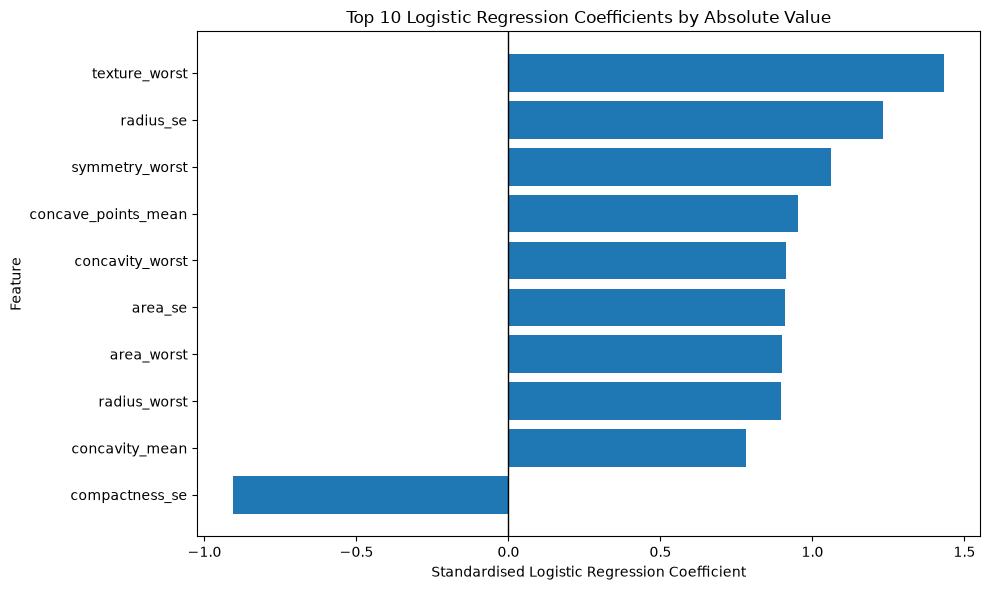

In [37]:

import matplotlib.pyplot as plt

# Select the 10 coefficients with the largest absolute values
top_coefficients = coefficient_df.loc[
    coefficient_df['Coefficient'].abs().nlargest(10).index
].sort_values('Coefficient')

# Plot coefficient values
plt.figure(figsize=(10, 6))

plt.barh(
    top_coefficients['Feature'],
    top_coefficients['Coefficient']
)

plt.axvline(0, color='black', linewidth=1)
plt.title('Top 10 Logistic Regression Coefficients by Absolute Value')
plt.xlabel('Standardised Logistic Regression Coefficient')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()


### Model Limitations and Recommendations

Although the Logistic Regression model achieved strong results, several limitations should be considered. The dataset contains only 569 observations, which may limit how well the findings generalise to other patient populations. The data also does not specifically represent South African patients, so the model's performance in local healthcare settings remains uncertain.The correlation analysis identified strong relationships between several predictors, which may affect the stability and interpretation of the regression coefficients. In addition, the model incorrectly classified three malignant tumours as benign, highlighting the risk of missed diagnoses.

To improve the model, future work could investigate different classification thresholds to reduce false negatives, while monitoring the effect on false positives. Regularisation and further feature selection could also be explored to address multicollinearity. Testing the model on larger, independent datasets, including South African patient data where available, would help assess its reliability and generalisability.